# Exercise 3
Nico Reiterer - 5191 2112

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

## 3.2

In [3]:
# Data knots given
x = np.array([0, 1, 2, 3, 4], dtype=float)
f = np.array([0, 1, 1, 2, 2], dtype=float)

n = len(x) - 1          # number of intervals
h = np.diff(x)          # interval lengths h_i
N = 4 * n               # number of unknowns


def idx(i, k):
    """Column index of coefficient k (0=a, 1=b, 2=c, 3=d) of piece i."""
    return 4 * i + k


M = np.zeros((N, N))
r = np.zeros(N)
row = 0

# Interpolation at the left end of each piece: a_i = f_i
for i in range(n):
    M[row, idx(i, 0)] = 1
    r[row] = f[i]
    row += 1

# Interpolation at the last knot: s_{n-1}(x_n) = f_n
i = n - 1
M[row, idx(i, 0)] = 1
M[row, idx(i, 1)] = h[i]
M[row, idx(i, 2)] = h[i] ** 2
M[row, idx(i, 3)] = h[i] ** 3
r[row] = f[n]
row += 1

# Smoothness at the interior knots x_1, ..., x_{n-1}
for i in range(n - 1):
    # j=0, no derivative : a_i + b_i h_i + c_i h_i^2 + d_i h_i^3 = a_{i+1}
    M[row, idx(i, 0)] = 1
    M[row, idx(i, 1)] = h[i]
    M[row, idx(i, 2)] = h[i] ** 2
    M[row, idx(i, 3)] = h[i] ** 3
    M[row, idx(i + 1, 0)] = -1
    row += 1

    # j=1: b_i + 2 c_i h_i + 3 d_i h_i^2 = b_{i+1}
    M[row, idx(i, 1)] = 1
    M[row, idx(i, 2)] = 2 * h[i]
    M[row, idx(i, 3)] = 3 * h[i] ** 2
    M[row, idx(i + 1, 1)] = -1
    row += 1

    # j=2: 2 c_i + 6 d_i h_i = 2 c_{i+1}
    M[row, idx(i, 2)] = 2
    M[row, idx(i, 3)] = 6 * h[i]
    M[row, idx(i + 1, 2)] = -2
    row += 1

# Not-a-knot: d_0 = d_1 and d_{n-2} = d_{n-1}
M[row, idx(0, 3)] = 1
M[row, idx(1, 3)] = -1
row += 1
M[row, idx(n - 2, 3)] = 1
M[row, idx(n - 1, 3)] = -1
row += 1

assert row == N, "number of equations must equal number of unknowns"

if __name__ == "__main__":
    np.set_printoptions(linewidth=200)
    print("M =\n", M.astype(int))
    print("r =", r)

    z = np.linalg.solve(M, r)
    coeffs = z.reshape(n, 4)   # row i = (a_i, b_i, c_i, d_i)
    print("\nCoefficients (a_i, b_i, c_i, d_i) per piece:\n", coeffs)

    # Check against scipy (default boundary condition = not-a-knot).
    # cs.c[:, i] stores (d_i, c_i, b_i, a_i), highest power first for some reason 
    # (although I naturally would write the highest power first, only in the 
    # script we start with a0 ... )
    cs = CubicSpline(x, f)
    print("\nMatches scipy CubicSpline:", np.allclose(coeffs, cs.c[::-1].T))

M =
 [[ 1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0  1  1  1  1]
 [ 1  1  1  1 -1  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  1  2  3  0 -1  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  2  6  0  0 -2  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  1  1  1  1 -1  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  1  2  3  0 -1  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  2  6  0  0 -2  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  1  1  1  1 -1  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  1  2  3  0 -1  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  2  6  0  0 -2  0]
 [ 0  0  0  1  0  0  0 -1  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  1  0  0  0 -1]]
r = [0. 1. 1. 2. 2. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Coefficients (a_i, b_i, c_i, d_i) per piece:
 [[ 0.   2.5 -2.   0.5]
 [ 1.   0.  -0.5  0.5]
 [ 1.   0.5  1.  -0.5]
 [ 2.   

## 3.3

In [4]:
n_list = np.array([10, 20, 40])

# defining the knots
x_unif = lambda n: 5 * (-1 + 2 * np.arange(n + 1) / n)
x_cheb = lambda n: 5 * np.cos((np.arange(n + 1) + 0.5)/(n+1) * np.pi)

# defining the function to interpolate
f = lambda x: (1 + x**2)**(-1)

# defining Neville as in last exercise
def N(f: np.ndarray, x: np.ndarray, x_dash: float) -> np.ndarray:
    """
    Algorithm 1 (Aitken-Neville Scheme) from p.5 of the script

        f: vector f ∈ Rn+
        x: knot vector x ∈ Rn+1
    
    """
    n = len(x)
    N = np.zeros((n, n)) # or rather np.full((n, n), np.nan) because zero could be a value ofc
    N[:,0] = f

    for m in range(1, n):
        for j in range(0, n - m):
            p_jm = (x_dash - x[j]) * N[j + 1, m - 1] - (x_dash - x[j+m]) * N[j, m - 1]
            p_jm /= (x[j+m] - x[j])
            N[j, m] =  p_jm
    
    return N

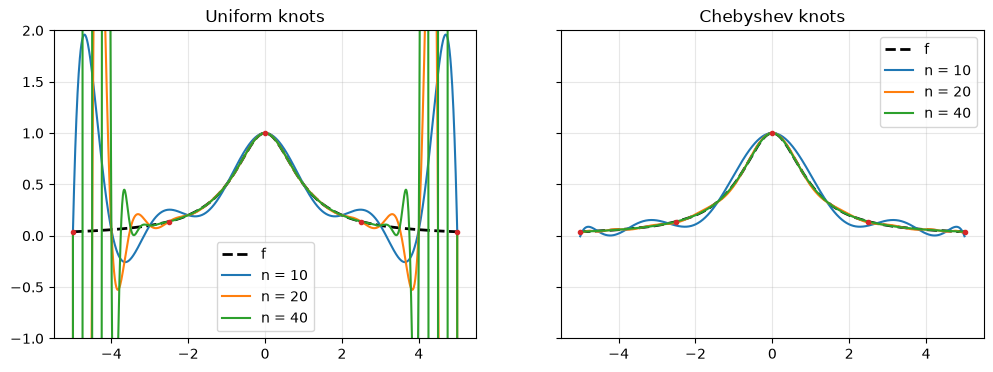

In [5]:
xe = np.linspace(-5, 5, 1001)

p_cheb = np.array([[N(f(x_cheb(n)), x_cheb(n), t)[0, -1] for t in xe] for n in n_list])
p_unif = np.array([[N(f(x_unif(n)), x_unif(n), t)[0, -1] for t in xe] for n in n_list])
# shapes: (len(n_list), len(xe))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, P, name in zip(axes, [p_unif, p_cheb], ["Uniform", "Chebyshev"]):
    ax.plot(xe, f(xe), "k--", lw=2, label="f")
    ax.plot(xe, P.T, label=[f"n = {n}" for n in n_list])   # all n in one call
    ax.plot(x_unif(n), f(x_unif(n)), ".")
    ax.set_title(f"{name} knots"); ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylim(-1, 2)   # uniform n=40 blows up near +/-5 as expected, so clipping the view
plt.show()

### 3.3 b) Lebesgue constant

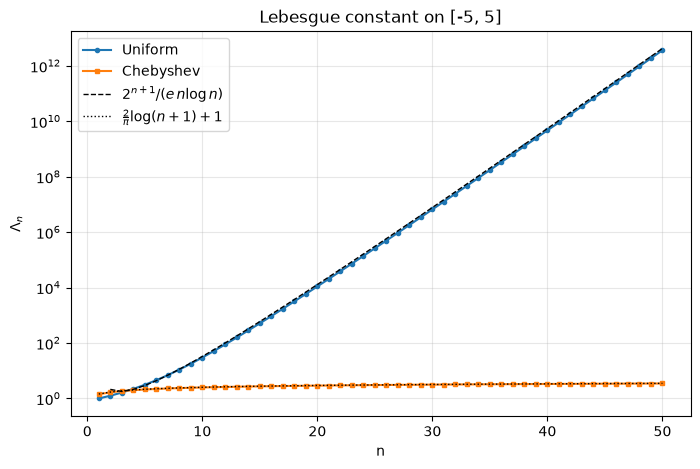

In [8]:
# Lebesgue constant: Lambda_n = max_x sum_i |l_i(x)|
def lagrange_basis(x: np.ndarray, t: np.ndarray) -> np.ndarray:
    """All Lagrange basis polynomials l_i evaluated at t, shape (len(x), len(t))."""
    D = t[None, :] - x[:, None]          # D[j, k] = t_k - x_j
    L = np.empty((len(x), len(t)))
    for i in range(len(x)):
        others = np.delete(np.arange(len(x)), i)
        L[i] = np.prod(D[others], axis=0) / np.prod(x[i] - x[others])
    return L

lebesgue = lambda x, t: np.abs(lagrange_basis(x, t)).sum(axis=0).max()

t = np.linspace(-5, 5, 5001)   # fine grid to approximate the max
n_range = np.arange(1, 51)
L_unif = np.array([lebesgue(x_unif(n), t) for n in n_range])
L_cheb = np.array([lebesgue(x_cheb(n), t) for n in n_range])

plt.figure(figsize=(8, 5))
plt.semilogy(n_range, L_unif, "o-", ms=3, label="Uniform")
plt.semilogy(n_range, L_cheb, "s-", ms=3, label="Chebyshev")
# known asymptotics for comparison
plt.semilogy(n_range[1:], 2**(n_range[1:] + 1) / (np.e * n_range[1:] * np.log(n_range[1:])), "k--", lw=1,
             label=r"$2^{n+1}/(e\,n\log n)$")
plt.semilogy(n_range, 2 / np.pi * np.log(n_range + 1) + 1, "k:", lw=1, label=r"$\frac{2}{\pi}\log(n+1)+1$")
plt.xlabel("n"); plt.ylabel(r"$\Lambda_n$"); plt.title("Lebesgue constant on [-5, 5]")
plt.legend(); plt.grid(alpha=0.3, which="both")
plt.show()

**Observation:** For uniform knots $\Lambda_n$ grows exponentially (a straight line in semilogy, roughly $2^{n+1}/(e\,n\log n)$), e.g. $\Lambda_{20}\approx 1.1\cdot 10^4$, $\Lambda_{40}\approx 4.7\cdot 10^9$. For Chebyshev knots it grows only logarithmically, $\Lambda_n \approx \frac{2}{\pi}\log n$ ($\Lambda_{40}\approx 3.3$). Since $\|f-p_n\|_\infty \le (1+\Lambda_n)\,\|f-p^*_n\|_\infty$, this explains the Runge phenomenon in 3.3: uniform interpolation can amplify errors (and rounding errors in the data) enormously, while Chebyshev interpolation is near-optimal.

## 3.3 c)

In [55]:
lebesgue    = lambda x, t: np.abs(lagrange_basis(x, t)).sum(axis=0).max()
appr_L_unif = lambda C, b, n: C * np.exp(b * n)


t = np.linspace(-5, 5, 5001)   
n_range = [20, 40]
L_unif = np.array([lebesgue(x_unif(n), t) for n in n_range])

# polyfit outputs from the highest power down (so b first)
b, log_C = np.polyfit(n_range, np.log(L_unif), 1)


print("Λ₂₀      =", L_unif[0], 
      "\nΛ₄₀      =", L_unif[1])

print("log(Λ₂₀) =", np.log(L_unif)[0], 
      "\nlog(Λ₄₀) =", np.log(L_unif)[1])

print("b        =", b, "\nlog(C)   =", log_C)


print("\nApproximated lambdas: ", 
      "\nΛ₂₀      =", appr_L_unif(np.exp(log_C), b, 20),
      "\nΛ₄₀      =",appr_L_unif(np.exp(log_C), b, 40))




Λ₂₀      = 10986.65740631479 
Λ₄₀      = 4692428643.184265
log(Λ₂₀) = 9.304436852483109 
log(Λ₄₀) = 22.2692161197423
b        = 0.6482389633629593 
log(C)   = -3.660342414776072

Approximated lambdas:  
Λ₂₀      = 10986.657406314831 
Λ₄₀      = 4692428643.184267


In [ ]:
appr_L_unif(np.exp(log_C), b, 20)
appr_L_unif(np.exp(log_C), b, 40)


## 3.4 Natural Cubic spine on an oscillatory function
$f(x) = cos(\pi*x) + \frac{1}{4}cos(3\pi*x)$

_Data below was calculated on paper_

In [56]:
from scipy.interpolate import CubicSpline
 
# Problem 3.4 a): knots -1, 0, 1, 
x = np.array([-1.0, 0.0, 1.0])
f = lambda t: np.cos(np.pi * t) + 0.25 * np.cos(3 * np.pi * t)
y = f(x)                      # (-5/4, 5/4, -5/4)
 
# Unknowns z = (a0, b0, c0, d0, a1, b1, c1, d1)
 
# The six rows shared by both splines (in terms of natural condition vs clamped condition)
common = np.array([
    # a0 b0 c0 d0 a1 b1 c1 d1
    [1, 0, 0, 0, 0, 0, 0, 0],   # a0 = f(-1)
    [0, 0, 0, 0, 1, 0, 0, 0],   # a1 = f(0)
    [0, 0, 0, 0, 1, 1, 1, 1],   # a1 + b1 + c1 + d1 = f(1)
    [1, 1, 1, 1, -1, 0, 0, 0],  # C^0 at 0: a0 + b0 + c0 + d0 = a1
    [0, 1, 2, 3, 0, -1, 0, 0],  # C^1 at 0: b0 + 2c0 + 3d0 = b1
    [0, 0, 2, 6, 0, 0, -2, 0],  # C^2 at 0: 2c0 + 6d0 = 2c1
    ], dtype=float)

rhs_common = np.array([y[0], y[1], y[2], 0, 0, 0])
 
# Natural: c0 = 0,  2c1 + 6d1 = 0
natural_rows = np.array([
    [0, 0, 1, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 2, 6],
], dtype=float)
rhs_natural = np.array([0.0, 0.0])
 
# Clamped: b0 = f'(-1) = 0,  b1 + 2c1 + 3d1 = f'(1) = 0
clamped_rows = np.array([
    [0, 1, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 1, 2, 3],
], dtype=float)
rhs_clamped = np.array([0.0, 0.0])
 
M_nat = np.vstack([common, natural_rows])
r_nat = np.concatenate([rhs_common, rhs_natural])
M_cl = np.vstack([common, clamped_rows])
r_cl = np.concatenate([rhs_common, rhs_clamped])

In [57]:
for name, M, r, bc in [
        ("natural", M_nat, r_nat, "natural"),
        ("clamped", M_cl, r_cl, ((1, 0.0), (1, 0.0))),
    ]:
        z = np.linalg.solve(M, r)
        coeffs = z.reshape(2, 4)          # row i = (a_i, b_i, c_i, d_i)
        print(f"--- {name} ---")
        print("M =\n", M)
        print("r =", r)
        print("coefficients (a_i, b_i, c_i, d_i):\n", coeffs)
        cs = CubicSpline(x, y, bc_type=bc)
        print("matches scipy:", np.allclose(coeffs, cs.c[::-1].T), "\n")

--- natural ---
M =
 [[ 1.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  1.  0.  0.  0.]
 [ 0.  0.  0.  0.  1.  1.  1.  1.]
 [ 1.  1.  1.  1. -1.  0.  0.  0.]
 [ 0.  1.  2.  3.  0. -1.  0.  0.]
 [ 0.  0.  2.  6.  0.  0. -2.  0.]
 [ 0.  0.  1.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  2.  6.]]
r = [-1.25  1.25 -1.25  0.    0.    0.    0.    0.  ]
coefficients (a_i, b_i, c_i, d_i):
 [[-1.25000000e+00  3.75000000e+00  0.00000000e+00 -1.25000000e+00]
 [ 1.25000000e+00 -1.38777878e-16 -3.75000000e+00  1.25000000e+00]]
matches scipy: True 

--- clamped ---
M =
 [[ 1.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  1.  0.  0.  0.]
 [ 0.  0.  0.  0.  1.  1.  1.  1.]
 [ 1.  1.  1.  1. -1.  0.  0.  0.]
 [ 0.  1.  2.  3.  0. -1.  0.  0.]
 [ 0.  0.  2.  6.  0.  0. -2.  0.]
 [ 0.  1.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  1.  2.  3.]]
r = [-1.25  1.25 -1.25  0.    0.    0.    0.    0.  ]
coefficients (a_i, b_i, c_i, d_i):
 [[-1.25000000e+00  0.00000000e+00  7.50000000e+00 -5.000000

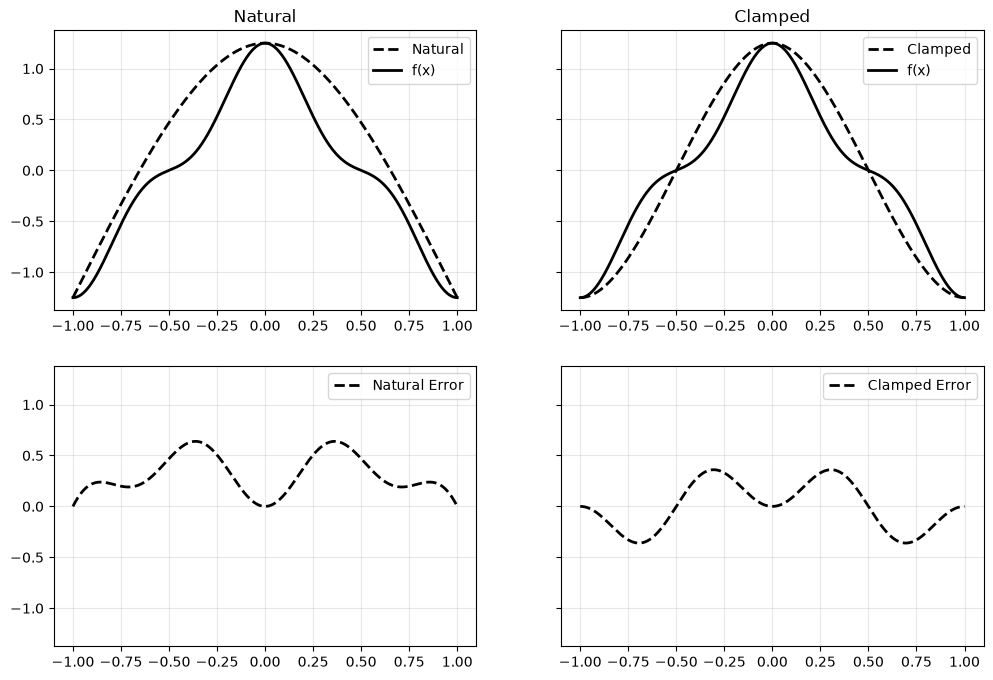

Max Error for Natural:
 0.638727601160696
Max Error for Clamped:
 0.36031328137501895


In [78]:
# Natural error
xe = np.linspace(-1, 1, 10001)

natural_coeffs = np.array([
    [-1.25000000e+00,  3.75000000e+00,  0.00000000e+00, -1.25000000e+00],
    [ 1.25000000e+00, -1.38777878e-16, -3.75000000e+00,  1.25000000e+00]
    ])

clamped_coeffs =  np.array([
    [-1.25000000e+00, 0.00000000e+00,  7.50000000e+00, -5.00000000e+00],
    [ 1.25000000e+00, 1.55431223e-16, -7.50000000e+00,  5.00000000e+00]
    ])


s = lambda ai, bi, ci, di, xi, x: ai + bi * (x - xi) + ci * (x - xi)**2 + di * (x - xi)**3

natural_y = np.where(xe <= 0,
                     s(*natural_coeffs[0], -1, xe),
                     s(*natural_coeffs[1],  0, xe))
clamped_y = np.where(xe <= 0,
                     s(*clamped_coeffs[0], -1, xe),
                     s(*clamped_coeffs[1],  0, xe))



fig, (row1, row2) = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for ax, y, name in zip(row1, [natural_y, clamped_y], ["Natural", "Clamped"]):
    ax.plot(xe, y, "k--", lw=2, label=name)
    ax.plot(xe, f(xe), "k-", lw=2, label="f(x)")
    ax.set_title(f"{name}") 
    ax.legend()
    ax.grid(alpha=0.3)

for ax, y, name in zip(row2, [natural_y, clamped_y], ["Natural", "Clamped"]):
    ax.plot(xe, y-f(xe), "k--", lw=2, label=f"{name} Error")
    ax.grid(alpha=0.3)
    ax.legend()

plt.show()

for y, name in zip([natural_y, clamped_y], ["Natural", "Clamped"]):
    print(f"Max Error for {name}:\n", np.max(np.abs(y-f(xe))))


In [ ]:
85 / 4 * np.pi**4 # showing the border is not really useful for h = 1...

2069.9431844725514

In [99]:
n_values = [8, 16, 32, 64, 128, 256]
x_values = [np.arange(n + 1) / n for n in n_values]
xe = np.linspace(0, 1, 10001)

g = lambda x: np.exp(-100 * (x - 1/5)**2) + 0.20 * np.sin(6 * np.pi * x)

# boundary conditions
dg = lambda x: -200 * (x - 1/5) * np.exp(-100 * (x - 1/5)**2) + 1.20 * np.pi * np.cos(6 * np.pi * x)

errors = {"natural": [], "clamped": []}

for name, bc in [
        ("natural", "natural"),
        ("clamped",  ((1, dg(0)), (1, dg(1)))),
    ]:

        for x in x_values:
            y = g(x)
            cs = CubicSpline(x, y, bc_type=bc)
            errors[name].append(np.max(np.abs(g(xe) - cs(xe))))


In [101]:
for name, e in errors.items():
    e = np.array(e)
    print(name, np.log2(e[:-1] / e[1:]))

natural [4.40903905 2.89867019 1.8885999  1.97821848 1.99496706]
clamped [4.2977947  4.63524872 4.25411724 4.07425293 4.01383086]


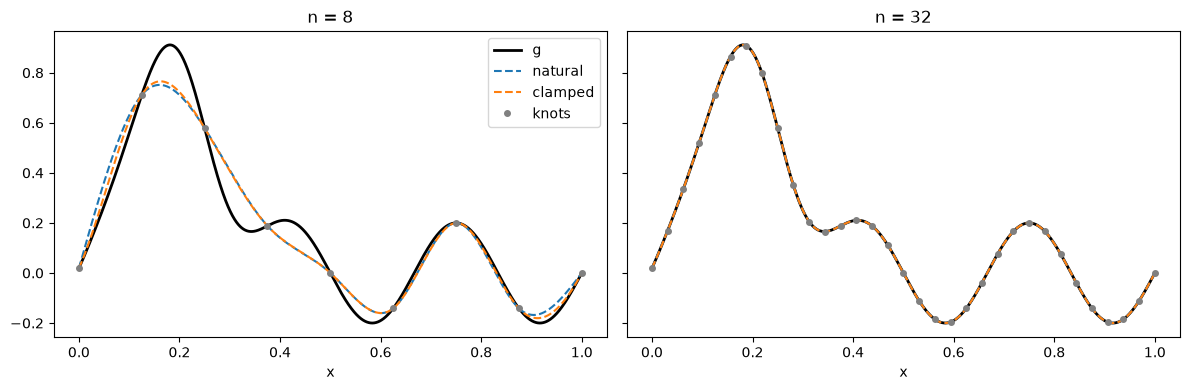

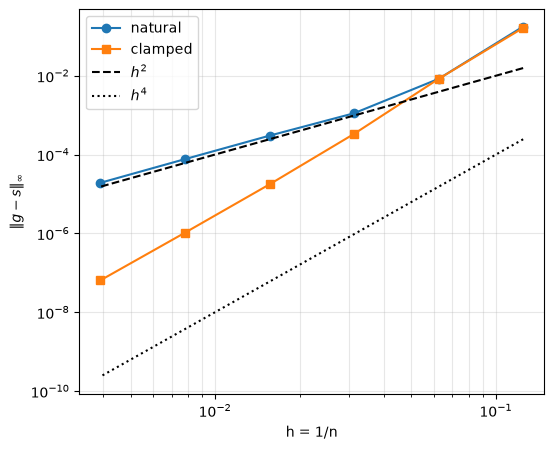

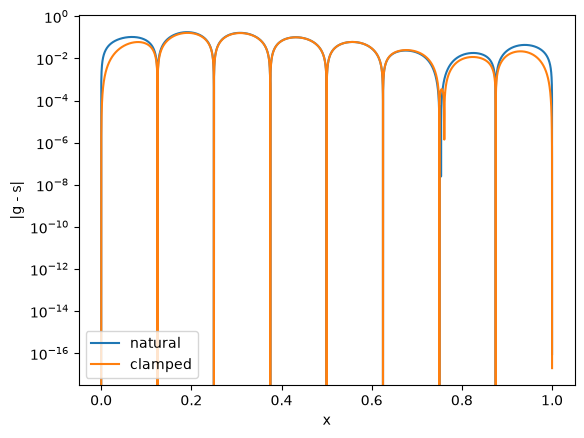

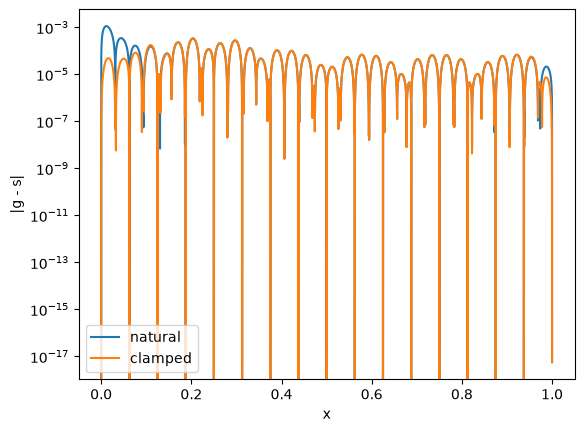

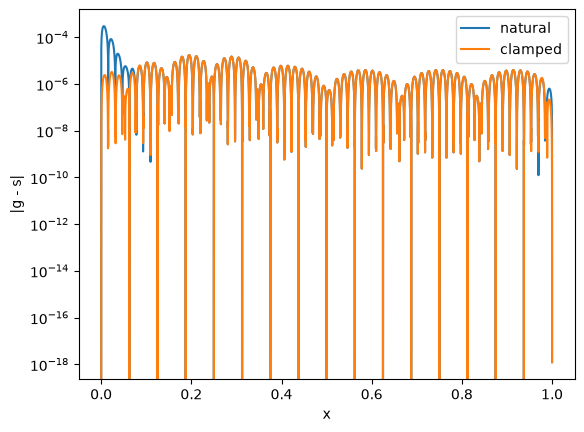

<Figure size 640x480 with 0 Axes>

In [116]:
import matplotlib.pyplot as plt

bcs = {"natural": "natural",
       "clamped": ((1, dg(0)), (1, dg(1)))}

# Figure 1: g and both splines for n = 8 and n = 32 ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, n in zip(axes, [8, 32]):
    x = np.arange(n + 1) / n
    ax.plot(xe, g(xe), "k", lw=2, label="g")
    for name, bc in bcs.items():
        cs = CubicSpline(x, g(x), bc_type=bc)
        ax.plot(xe, cs(xe), "--", label=name)
    ax.plot(x, g(x), "o", ms=4, color="gray", label="knots")
    ax.set_title(f"n = {n}")
    ax.set_xlabel("x")
axes[0].legend()
plt.tight_layout()
plt.show()

# Figure 2: max error vs h, loglog ---
h = 1 / np.array(n_values)
plt.figure(figsize=(6, 5))
plt.loglog(h, errors["natural"], "o-", label="natural")
plt.loglog(h, errors["clamped"], "s-", label="clamped")
plt.loglog(h, h**2, "k--", label=r"$h^2$")
plt.loglog(h, h**4, "k:",  label=r"$h^4$")
plt.xlabel("h = 1/n")
plt.ylabel(r"$\|g - s\|_\infty$")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

# Figure 3: Zoom in on the boundaries
n = 8
x = np.arange(n + 1) / n
plt.figure()
for name, bc in bcs.items():
    cs = CubicSpline(x, g(x), bc_type=bc)
    plt.semilogy(xe, np.abs(g(xe) - cs(xe)), label=name)
plt.xlabel("x"); plt.ylabel("|g - s|"); plt.legend()
plt.show()

n = 32
x = np.arange(n + 1) / n
plt.figure()
for name, bc in bcs.items():
    cs = CubicSpline(x, g(x), bc_type=bc)
    plt.semilogy(xe, np.abs(g(xe) - cs(xe)), label=name)
plt.xlabel("x"); plt.ylabel("|g - s|"); plt.legend()
plt.show()

n = 64
x = np.arange(n + 1) / n
plt.figure()
for name, bc in bcs.items():
    cs = CubicSpline(x, g(x), bc_type=bc)
    plt.semilogy(xe, np.abs(g(xe) - cs(xe)), label=name)
plt.xlabel("x"); plt.ylabel("|g - s|"); plt.legend()
plt.show()

axes[0].legend()
plt.tight_layout()
plt.show()